# 电商配送表现分析（E-commerce Delivery Performance Analysis）

## 项目目标

本项目基于 Olist 电商数据集，对订单配送表现进行探索性数据分析（EDA）。

主要希望回答以下问题：

- 订单通常需要多长时间完成配送？
- 有多少订单发生延迟配送？
- 延迟订单平均会延迟多少天？
- 商品数量、订单金额、运费等因素是否与配送延迟有关？

分析过程中主要使用 Python、Pandas 进行数据清洗、特征构建、数据聚合和多表合并，
并为后续 Dashboard 可视化准备核心指标。

In [2]:
import pandas as pd

## 1. 数据读取与初步探索（Data Loading & Exploration）

首先读取订单数据，并检查：

- 数据集的行数和列数
- 各字段的数据类型
- 缺失值情况
- 订单状态分布
- 日期字段是否能够正常用于时间计算

这一阶段的主要目的是了解数据结构，并发现可能影响后续分析的数据质量问题。

In [3]:
orders = pd.read_csv("../data/olist_orders_dataset.csv")

orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
orders.shape

(99441, 8)

In [5]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

In [6]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [7]:
orders.isnull()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
99436,False,False,False,False,False,False,False,False
99437,False,False,False,False,False,False,False,False
99438,False,False,False,False,False,False,False,False
99439,False,False,False,False,False,False,False,False


In [8]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [9]:
orders.isnull().sum()/len(orders)*100

order_id                         0.000000
customer_id                      0.000000
order_status                     0.000000
order_purchase_timestamp         0.000000
order_approved_at                0.160899
order_delivered_carrier_date     1.793023
order_delivered_customer_date    2.981668
order_estimated_delivery_date    0.000000
dtype: float64

In [10]:
orders['order_status'].unique()

<StringArray>
[  'delivered',    'invoiced',     'shipped',  'processing', 'unavailable',
    'canceled',     'created',    'approved']
Length: 8, dtype: str

In [11]:
orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [12]:
missing_delivery = orders[
    orders['order_delivered_customer_date'].isnull()
]

missing_delivery.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00
44,ee64d42b8cf066f35eac1cf57de1aa85,caded193e8e47b8362864762a83db3c5,shipped,2018-06-04 16:44:48,2018-06-05 04:31:18,2018-06-05 14:32:00,NaN,2018-06-28 00:00:00
103,0760a852e4e9d89eb77bf631eaaf1c84,d2a79636084590b7465af8ab374a8cf5,invoiced,2018-08-03 17:44:42,2018-08-07 06:15:14,NaN,NaN,2018-08-21 00:00:00
128,15bed8e2fec7fdbadb186b57c46c92f2,f3f0e613e0bdb9c7cee75504f0f90679,processing,2017-09-03 14:22:03,2017-09-03 14:30:09,NaN,NaN,2017-10-03 00:00:00
154,6942b8da583c2f9957e990d028607019,52006a9383bf149a4fb24226b173106f,shipped,2018-01-10 11:33:07,2018-01-11 02:32:30,2018-01-11 19:39:23,NaN,2018-02-07 00:00:00


In [13]:
missing_delivery['order_status'].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [14]:
delivered_but_missing = orders[(
    orders['order_status'] == 'delivered' 
)&
(orders['order_delivered_customer_date'].isnull())]

delivered_but_missing

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


In [15]:
delivered_but_missing.shape

(8, 8)

## 2. 数据质量检查（Data Quality Check）

在进行配送表现分析之前，首先检查订单数据的完整性和质量。

本阶段主要检查：

- 各字段的缺失值数量及缺失比例
- 订单状态的分布情况
- 已完成配送（delivered）订单中的关键字段是否存在缺失
- 可能影响后续配送时间计算的数据异常

对于存在缺失的配送相关字段，需要结合订单状态进一步判断，而不是直接删除。

In [16]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [17]:
orders.isnull().mean().sort_values(ascending=False)*100

order_delivered_customer_date    2.981668
order_delivered_carrier_date     1.793023
order_approved_at                0.160899
order_id                         0.000000
customer_id                      0.000000
order_status                     0.000000
order_purchase_timestamp         0.000000
order_estimated_delivery_date    0.000000
dtype: float64

In [18]:
orders[orders['order_delivered_customer_date'].isnull()]['order_status'].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [19]:
delivered_missing  = orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_customer_date'].isnull())
]

delivered_missing

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


In [20]:
delivered_missing[
    [
        'order_id',
        'order_status',
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
]

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


In [21]:
delivered_orders = orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_customer_date'].notnull())
].copy()

delivered_orders.shape

(96470, 8)

In [22]:
delivered_orders[
    [
        'order_purchase_timestamp',
        'order_delivered_customer_date',
        'order_estimated_delivery_date',
        'order_approved_at',
        'order_delivered_carrier_date'
    ]
].dtypes

order_purchase_timestamp         str
order_delivered_customer_date    str
order_estimated_delivery_date    str
order_approved_at                str
order_delivered_carrier_date     str
dtype: object

In [23]:
date_columns = delivered_orders[
    [
        'order_purchase_timestamp',
        'order_delivered_customer_date',
        'order_estimated_delivery_date',
        'order_approved_at',
        'order_delivered_carrier_date'
    ]
]

for col in date_columns:
    delivered_orders[col] = pd.to_datetime(delivered_orders[col])

## 3. 配送时间分析（Delivery Time Analysis）

为了衡量订单从下单到实际送达所需要的时间，构建配送时间指标
`delivery_time_days`。

计算方式：

**配送时间 = 实际送达时间 - 下单时间**

通过该指标分析订单整体配送效率，并进一步检查配送时间的分布及潜在异常值

In [24]:
delivered_orders['delivery_time_days'] = (
    delivered_orders['order_delivered_customer_date']
    - delivered_orders['order_purchase_timestamp']
).dt.total_seconds() / 86400

In [25]:
delivered_orders['delivery_time_days'].describe()

count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_time_days, dtype: float64

### 初步发现

已完成配送订单的平均配送时间约为 **12.56 天**，中位数约为 **10.22 天**。

平均值高于中位数，说明配送时间分布存在一定右偏，部分配送时间较长的订单拉高了整体平均值。

其中最长配送时间约为 **209.63 天**，明显高于正常配送时间，因此下一步需要进一步检查潜在异常值。

In [26]:
delivered_orders['delivery_time_days'].isna().sum()

np.int64(0)

In [27]:
delivered_orders['delivery_time_days'].min()

np.float64(0.5334143518518518)

In [28]:
delivered_orders['delivery_time_days'].max()

np.float64(209.6286111111111)

### 3.1 配送时间异常值检测（IQR Method）

由于配送时间的最大值明显高于正常水平，因此使用四分位距（IQR）方法识别潜在异常值。

计算方式：

**IQR = Q3 - Q1**

异常值判断范围：

- 下界：Q1 - 1.5 × IQR
- 上界：Q3 + 1.5 × IQR

需要注意的是，统计意义上的异常值并不一定代表错误数据。
对于配送业务而言，较长的配送时间可能反映真实的物流异常，因此需要进一步检查，而不是直接删除。

In [29]:
q1 = delivered_orders['delivery_time_days'].quantile(0.25)
q3 = delivered_orders['delivery_time_days'].quantile(0.75)

iqr = q3 - q1 

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print('Q1',q1)
print('Q3',q3)
print('IQR:', iqr)
print('Lower_bound:',lower_bound)
print('Upper_bound:',upper_bound)

Q1 6.766203703703704
Q3 15.720182291666667
IQR: 8.953978587962963
Lower_bound: -6.664764178240739
Upper_bound: 29.15115017361111


In [30]:
delivery_outliers = delivered_orders[
    (delivered_orders['delivery_time_days'] < lower_bound)|
    (delivered_orders['delivery_time_days'] > upper_bound)
]

delivery_outliers.shape

(4896, 9)

In [31]:
delivery_outliers.sort_values('delivery_time_days',ascending = False).head(10)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time_days
19590,ca07593549f1816d26a572e06dc1eab6,75683a92331068e2d281b11a7866ba44,delivered,2017-02-21 23:31:27,2017-02-23 02:35:15,2017-03-08 13:47:46,2017-09-19 14:36:39,2017-03-22,209.628611
55619,1b3190b2dfa9d789e1f14c05b647a14a,d306426abe5fca15e54b645e4462dc7b,delivered,2018-02-23 14:57:35,2018-02-23 15:16:14,2018-02-26 18:49:07,2018-09-19 23:24:07,2018-03-15,208.351759
61610,440d0d17af552815d15a9e41abe49359,7815125148cfa1e8c7fee1ff7974f16c,delivered,2017-03-07 23:59:51,2017-03-09 01:11:33,2017-03-15 13:00:08,2017-09-19 15:12:50,2017-04-07,195.634016
70307,2fb597c2f772eca01b1f5c561bf6cc7b,217906bc11a32c1e470eb7e08584894b,delivered,2017-03-08 18:09:02,2017-03-08 18:09:02,2017-03-13 08:54:02,2017-09-19 14:33:17,2017-04-17,194.850174
89130,285ab9426d6982034523a855f55a885e,9cf2c3fa2632cee748e1a59ca9d09b21,delivered,2017-03-08 22:47:40,2017-03-08 22:47:40,2017-03-09 08:53:20,2017-09-19 14:00:04,2017-04-06,194.633611
38509,0f4519c5f1c541ddec9f21b3bddd533a,1a8a4a30dc296976717f44e7801fdeef,delivered,2017-03-09 13:26:57,2017-03-09 13:26:57,2017-03-22 05:28:14,2017-09-19 14:38:21,2017-04-11,194.049583
11399,47b40429ed8cce3aee9199792275433f,cb2caaaead400c97350c37a3fc536867,delivered,2018-01-03 09:44:01,2018-01-03 10:31:15,2018-02-06 01:48:28,2018-07-13 20:51:31,2018-01-19,191.463542
81401,2fe324febf907e3ea3f2aa9650869fa5,65b14237885b3972ebec28c0f7dd2220,delivered,2017-03-13 20:17:10,2017-03-13 20:17:10,2017-03-17 07:23:53,2017-09-19 17:00:07,2017-04-05,189.863160
54480,2d7561026d542c8dbd8f0daeadf67a43,8199345f57c6d1cbe9701f92481beb8d,delivered,2017-03-15 11:24:27,2017-03-15 11:24:27,2017-03-16 09:29:16,2017-09-19 14:38:18,2017-04-13,188.134618
68769,c27815f7e3dd0b926b58552628481575,f85e9ec0719b16dc4dd0edd438793553,delivered,2017-03-15 23:23:17,2017-03-15 23:23:17,2017-03-21 14:50:25,2017-09-19 17:14:25,2017-04-10,187.743843


#### 异常值检查结果

IQR 方法得到的配送时间上界约为 **29.15 天**，共有 **4,896 个订单**
被识别为潜在异常值。

部分订单的配送时间超过 190 天，最长约为 209.63 天。

这些记录虽然属于统计意义上的异常值，但可能反映真实的严重配送延迟。
因此，本分析暂时保留这些订单，而不是直接删除，并在后续延迟配送分析中进一步研究。

## 4. 延迟配送分析（Late Delivery Analysis）

配送时间较长并不一定意味着订单发生了延迟，因为不同订单的预计送达时间不同。

因此，本部分将实际送达日期与预计送达日期进行比较，构建以下指标：

- `delay_days`：实际送达日期与预计送达日期之间的时间差
- `is_late`：订单是否超过预计送达日期

其中：

- `delay_days < 0`：提前送达
- `delay_days > 0`：延迟送达

In [32]:
delivered_orders['delay_days'] = (
    delivered_orders['order_delivered_customer_date']
    - delivered_orders['order_estimated_delivery_date']
).dt.total_seconds() / 86400

In [33]:
delivered_orders['delay_days'].describe()

count    96470.000000
mean       -11.178126
std         10.184354
min       -146.016123
25%        -16.244065
50%        -11.948102
75%         -6.389815
max        188.975081
Name: delay_days, dtype: float64

In [34]:
delivered_orders['is_late'] = (
    delivered_orders['delay_days'] > 0
)

In [35]:
delivered_orders['is_late'].value_counts()

is_late
False    88644
True      7826
Name: count, dtype: int64

In [36]:
delivered_orders['is_late'].value_counts(normalize= True) * 100

is_late
False    91.887633
True      8.112367
Name: proportion, dtype: float64

In [37]:
late_orders = delivered_orders[
    delivered_orders['is_late'] == True
]

In [38]:
late_orders['delay_days'].describe()

count    7826.000000
mean        9.551776
std        13.952540
min         0.002500
25%         1.867179
50%         5.806481
75%        11.820978
max       188.975081
Name: delay_days, dtype: float64

In [39]:
late_orders.sort_values(
    'delay_days',
    ascending = False
)[
    [
        'order_id',
        'order_purchase_timestamp',
        'order_estimated_delivery_date',
        'order_delivered_customer_date',
        'delivery_time_days',
        'delay_days'
    ]
].head(10)

,order_id,order_purchase_timestamp,order_estimated_delivery_date,order_delivered_customer_date,delivery_time_days,delay_days
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:35,2018-03-15,2018-09-19 23:24:07,208.351759,188.975081
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:27,2017-03-22,2017-09-19 14:36:39,209.628611,181.608785
11399,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:01,2018-01-19,2018-07-13 20:51:31,191.463542,175.869109
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:10,2017-04-05,2017-09-19 17:00:07,189.863160,167.708414
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-04-06,2017-09-19 14:00:04,194.633611,166.583380
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-04-07,2017-09-19 15:12:50,195.634016,165.633912
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:17,2017-04-10,2017-09-19 17:14:25,187.743843,162.718345
40847,d24e8541128cea179a11a65176e0a96f,2017-06-12 13:14:11,2017-06-26,2017-12-04 18:36:29,175.223819,161.775336
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-04-11,2017-09-19 14:38:21,194.049583,161.609965
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:27,2017-04-13,2017-09-19 14:38:18,188.134618,159.609931


In [40]:
avg_delay = late_orders['delay_days'].mean()

avg_delay

np.float64(9.551775917880569)

In [41]:
late_delivery_rate = delivered_orders['is_late'].mean() * 100
avg_delay = late_orders['delay_days'].mean()

print(f'Late Delivery Rate : {late_delivery_rate: .2f}%')
print(f'Average Delay: {avg_delay:.2f} days')

Late Delivery Rate :  8.11%
Average Delay: 9.55 days


### 4.1 核心配送 KPI（Delivery KPIs）

分析结果显示：

- **延迟配送率（Late Delivery Rate）：8.11%**
- **准时或提前送达率：91.89%**
- **延迟订单平均延迟时间（Average Delay）：9.55 天**

整体来看，大多数订单能够在预计日期前完成配送。

但约 **8.11%** 的订单存在延迟，并且发生延迟的订单平均超过预计日期约 **9.55 天**，
说明延迟订单虽然占比较低，但延迟程度仍然值得进一步分析。

## 5. 订单级特征构建（Order-Level Feature Engineering）

为了进一步分析影响配送延迟的潜在因素，本部分引入订单商品数据 `order_items`。

该数据集包含商品、卖家、价格、运费等信息，可以用于构建订单层面的业务特征。

在进行数据合并之前，需要首先确认不同数据表的数据粒度（Data Grain），
避免由于一对多关系导致订单被重复计算。

### 5.1 数据粒度检查（Data Grain Check）

`order_items` 数据集中的一行代表一个订单中的一个商品，而不是一个完整订单。

数据集中共有 **112,650 条商品记录**，但只有 **98,666 个唯一订单**，
说明部分订单包含多个商品。

因此，如果直接将 `order_items` 与订单表进行合并，
可能导致同一个订单出现多行，从而影响延迟配送率等订单级指标。

为保持“一行 = 一个订单”的分析粒度，需要先对商品数据进行聚合。

In [42]:
order_items = pd.read_csv('../data/olist_order_items_dataset.csv')

order_items.shape

(112650, 7)

In [43]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [44]:
order_items['order_id'].nunique()

98666

In [45]:
items_per_order = (
    order_items
    .groupby('order_id')
    .size()
    .reset_index(name = 'item_count')
)

items_per_order.head()

,order_id,item_count
0,00010242fe8c5a6d1ba2dd792cb16214,1
1,00018f77f2f0320c557190d7a144bdd3,1
2,000229ec398224ef6ca0657da4fc703e,1
3,00024acbcdf0a6daa1e931b038114c75,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,1


In [46]:
items_per_order.shape

(98666, 2)

### 5.2 商品数据聚合（Order-Level Aggregation）

按照 `order_id` 对商品记录进行聚合，并构建三个订单级特征：

- `item_count`：订单包含的商品数量
- `total_price`：订单商品总金额
- `total_freight`：订单总运费

聚合后，每个 `order_id` 只保留一行，从而与订单数据保持一致的数据粒度

In [47]:
order_summary = (
    order_items
    .groupby('order_id')
    .agg(
        item_count = ('order_item_id','count'),
        total_price=('price','sum'),
        total_freight = ('freight_value','sum')
    )
    .reset_index()
)

order_summary.head()

,order_id,item_count,total_price,total_freight
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14


In [48]:
order_summary.shape

(98666, 4)

In [49]:
order_summary[['item_count','total_price','total_freight']].describe()

,item_count,total_price,total_freight
count,98666.000000,98666.000000,98666.000000
mean,1.141731,137.754076,22.823562
std,0.538452,210.645145,21.650909
min,1.000000,0.850000,0.000000
25%,1.000000,45.900000,13.850000
50%,1.000000,86.900000,17.170000
75%,1.000000,149.900000,24.040000
max,21.000000,13440.000000,1794.960000


### 5.3 合并订单与配送数据（Data Merge）

将订单级商品特征与配送数据通过 `order_id` 进行左连接（Left Join）。

合并后检查：

- 数据行数是否发生变化
- `order_id` 是否仍然唯一
- 新增字段是否存在缺失值

这些检查用于确认合并过程没有产生重复订单或数据丢失。

In [50]:
delivery_analysis = delivered_orders.merge(
    order_summary,
    on = 'order_id',
    how = 'left'
)

In [51]:
delivery_analysis.shape

(96470, 14)

In [52]:
delivery_analysis[
    ['item_count','total_price','total_freight']
].isna().sum()

item_count       0
total_price      0
total_freight    0
dtype: int64

In [53]:
delivery_analysis['order_id'].nunique()

96470

#### 合并结果

合并后的数据集包含 **96,470 个已完成配送订单**。

合并前后的订单数量保持一致，并且 `order_id` 仍然唯一；
`item_count`、`total_price` 和 `total_freight` 均不存在缺失值。

因此，本次合并没有产生订单重复或订单级数据丢失，
可以继续用于后续配送影响因素分析。

## 6. 配送延迟影响因素分析（Delivery Delay Factors）

### 6.1 商品数量与配送表现

In [54]:
delivery_analysis['item_count'].value_counts().sort_index()

item_count
1     86835
2      7392
3      1306
4       495
5       193
6       191
7        22
8         8
9         3
10        8
11        4
12        5
13        1
14        2
15        2
20        2
21        1
Name: count, dtype: int64

In [55]:
item_analysis = (
    delivery_analysis
    .groupby('item_count')
    .agg(
        order_count=('order_id','count'),
        late_delivery_rate=('is_late','mean'),
        avg_delivery_days=('delivery_time_days','mean')
    )
    .reset_index()
)

item_analysis['late_delivery_rate'] *= 100.0

item_analysis

,item_count,order_count,late_delivery_rate,avg_delivery_days
0,1,86835,8.288133,12.639136
1,2,7392,6.628788,11.826892
2,3,1306,6.202144,11.632372
3,4,495,5.656566,12.233637
4,5,193,6.735751,12.038005
5,6,191,8.376963,11.893492
6,7,22,0.000000,11.670133
7,8,8,0.000000,13.477030
8,9,3,0.000000,9.431424
9,10,8,0.000000,10.027878


In [56]:
delivery_analysis['item_group'] = pd.cut(
    delivery_analysis['item_count'],
    bins = [0,1,2,3,6,float('inf')],
    labels = ['1','2','3','4-6','7+']
)

In [57]:
item_group_analysis = (
    delivery_analysis 
    .groupby('item_group',observed= True)
    .agg(
        order_count = ('order_id','count'),
        late_delivery_rate =('is_late','mean'),
        avg_delivery_days =('delivery_time_days','mean'),
        avg_delay =('delay_days',lambda x : x[x>0].mean())
    )
    .reset_index()
)
item_group_analysis['late_delivery_rate'] *= 100.0

item_group_analysis

,item_group,order_count,late_delivery_rate,avg_delivery_days,avg_delay
0,1,86835,8.288133,12.639136,9.630608
1,2,7392,6.628788,11.826892,8.809526
2,3,1306,6.202144,11.632372,7.992139
3,4-6,879,6.484642,12.116771,8.296962
4,7+,58,1.724138,12.153383,3.752106


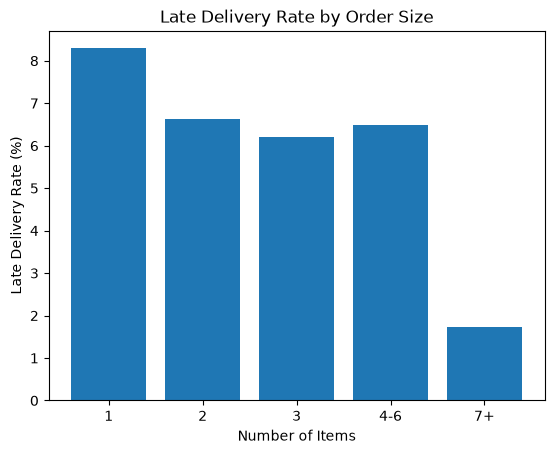

In [58]:
import matplotlib.pyplot as plt 

plt.bar(
    item_group_analysis['item_group'],
    item_group_analysis['late_delivery_rate']
)

plt.xlabel('Number of Items')
plt.ylabel('Late Delivery Rate (%)')
plt.title('Late Delivery Rate by Order Size')

plt.show()

#### 分析结论

从订单规模来看，1 件商品订单的延迟配送率约为 **8.29%**，
而 2 件、3 件及 4–6 件商品订单的延迟率约为 **6%–7%**。

整体上没有观察到“商品数量增加导致延迟率持续上升”的趋势。

7 件及以上商品订单的延迟率仅约为 **1.72%**，
但该组只有 **58 个订单**，样本量较小，因此不宜据此认为大订单具有更好的配送表现。

综合来看，**商品数量与配送延迟之间暂未表现出明显的正向关系，
商品数量可能不是解释配送延迟的主要因素。**

### 6.2 运费与配送表现

In [59]:
order_freight=(order_items.groupby('order_id')['freight_value'].sum().reset_index())

In [60]:
order_freight.head()

,order_id,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,13.29
1,00018f77f2f0320c557190d7a144bdd3,19.93
2,000229ec398224ef6ca0657da4fc703e,17.87
3,00024acbcdf0a6daa1e931b038114c75,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,18.14


In [61]:
freight_analysis = delivery_analysis.merge(
    order_freight,
    on = 'order_id',
    how = 'left',
    validate = 'one_to_one'
)

freight_analysis[
    ['order_id','freight_value','is_late']
].head()

,order_id,freight_value,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,8.72,False
1,53cdb2fc8bc7dce0b6741e2150273451,22.76,False
2,47770eb9100c2d0c44946d9cf07ec65d,19.22,False
3,949d5b44dbf5de918fe9c16f97b45f8a,27.20,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8.72,False


In [62]:
print('before merge:',len(delivery_analysis))
print('after merge:', len(freight_analysis))

print(
    'missing freight values:',
    freight_analysis['freight_value'].isna().sum()
)

print(
    'unique orders:',
    freight_analysis['order_id'].nunique()
)

before merge: 96470
after merge: 96470
missing freight values: 0
unique orders: 96470


In [63]:
freight_analysis['freight_group'] = pd.qcut(
    freight_analysis['freight_value'],
    q=4,
    duplicates='drop'
)

freight_analysis[
    ['freight_value','freight_group','is_late']
].head()

,freight_value,freight_group,is_late
0,8.72,"(-0.001, 13.85]",False
1,22.76,"(17.17, 24.02]",False
2,19.22,"(17.17, 24.02]",False
3,27.20,"(24.02, 1794.96]",False
4,8.72,"(-0.001, 13.85]",False


In [65]:
freight_summary = (
    freight_analysis
    .groupby('freight_group',observed=True)
    .agg(
        total_orders=('order_id','nunique'),
        late_rate = ('is_late','mean'),
        avg_freight =('freight_value','mean')
    )
    .reset_index()
)

freight_summary['late_rate_pct'] = (
    freight_summary['late_rate'] * 100
)

freight_summary 

,freight_group,total_orders,late_rate,avg_freight,late_rate_pct
0,"(-0.001, 13.85]",24153,0.060034,10.459786,6.003395
1,"(13.85, 17.17]",24091,0.081898,15.463615,8.189780
2,"(17.17, 24.02]",24112,0.090080,19.788770,9.007963
3,"(24.02, 1794.96]",24114,0.092519,45.443722,9.251887


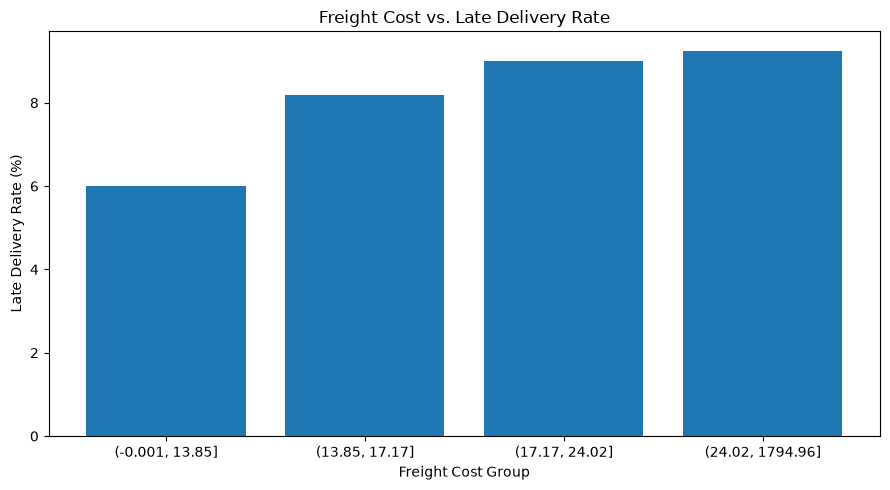

In [66]:
import matplotlib.pyplot as plt 

plt.figure(figsize=(9,5))

plt.bar(
    freight_summary['freight_group'].astype(str),
    freight_summary['late_rate_pct']
)

plt.xlabel('Freight Cost Group')
plt.ylabel('Late Delivery Rate (%)')
plt.title('Freight Cost vs. Late Delivery Rate')

plt.tight_layout()
plt.show()


6.2.2 运费水平与配送延迟率的关系

根据订单总运费的四分位数，将 96,470 笔订单划分为四个运费区间，并比较不同区间的配送延迟率。

分析结果显示，配送延迟率随运费水平升高呈逐步上升趋势。最低运费组的延迟率约为 6.00%，最高运费组约为 9.25%，两者相差约 3.25 个百分点。

这一结果表明，订单运费与配送延迟风险之间存在正向关联。但由于运费可能受到配送距离、商品重量、卖家位置等因素影响，因此不能据此认定运费升高会直接导致配送延迟。

后续可结合地区、配送距离及其他订单特征进一步分析，以判断这种关联是否依然存在。